# Laboratorio 3 — Secuencias: RNN y LSTM

**Universidad del Valle**
**Deep Learning y Sistemas Inteligentes — 2026**
**Kevin Recinos**

**Estudiante:** Pablo Cabrera — 231156

---

### Caso

El área de monitoreo transaccional de **Banco del Altiplano** quiere pasar de un sistema de reglas
sobre variables agregadas (promedio, máximo, conteo) a un modelo que lea la **secuencia** de movimientos
de una tarjeta. La sospecha del área de riesgos es concreta: hay patrones de fraude que solo se ven en el
orden — montos pequeños de prueba seguidos de una escalada rápida.

Usted va a construir, desde cero, la pieza que hace posible ese salto: una celda recurrente. Primero a mano
con NumPy, después verificada contra PyTorch, después una LSTM completa. Y al final va a **medir** hasta
qué distancia en el tiempo alcanza a aprender cada arquitectura.

### Cómo se trabaja

| Bloque | Qué va a hacer | Puntos |
|:--|:--|--:|
| 0 | **Investigar.** Lectura guiada y preguntas cortas, antes de escribir código. | 8 |
| 1–3 | **Desarrollar.** La celda recurrente, la salida y el alcance de la memoria, con NumPy. | 33 |
| 4 | **Verificar.** Ejecutar y comparar contra `torch.nn.RNN`. | 6 |
| 5 | **Desarrollar.** Una celda LSTM completa, a mano. | 14 |
| 6 | **Desarrollar y entrenar.** Una LSTM real sobre secuencias de transacciones. | 12 |
| 7 | **Investigar con evidencia.** ¿Hasta cuántos pasos atrás aprende cada arquitectura? | 14 |
| 8–9 | Análisis y conclusión, en sus propias palabras. | 13 |

**Todo se responde y se entrega dentro de este mismo notebook, con las celdas ejecutadas.**
Las celdas de `assert` son su verificación: si imprimen `OK`, el bloque está bien. Si fallan,
corrija antes de avanzar — los bloques posteriores dependen de los anteriores.

**Semanas:** 4 y 5 (laboratorio de dos semanas) · **Entrega:** viernes de la semana 5

In [1]:
import numpy as np

np.set_printoptions(precision=4, suppress=True)
print("NumPy:", np.__version__)

NumPy: 2.4.6


---
## Bloque 0 — Investigación previa (8 puntos)

Antes de escribir código, lea:

- **PyTorch — `torch.nn.RNN`**: https://pytorch.org/docs/stable/generated/torch.nn.RNN.html
- **PyTorch — `torch.nn.LSTM`**: https://pytorch.org/docs/stable/generated/torch.nn.LSTM.html
- **Understanding LSTM Networks** (Christopher Olah): https://colah.github.io/posts/2015-08-Understanding-LSTMs/

Responda con **sus propias palabras**, 2 a 4 líneas cada una. No copie de la documentación.

1. `nn.RNN` recibe tensores con forma `(seq_len, batch, input_size)` salvo que se pase `batch_first=True`.
   ¿Qué representa cada una de esas tres dimensiones, y por qué el valor por omisión es una fuente
   frecuente de errores silenciosos?
2. `nn.LSTM` devuelve `salida, (h_n, c_n)`. ¿Qué contiene cada uno de los tres, y cuál usaría para
   clasificar **la secuencia completa** como fraude o no fraude?
3. En la publicación de Olah, ¿qué papel cumple el **estado de celda** ($c_t$) y por qué el autor lo
   dibuja como una línea horizontal que atraviesa toda la celda sin ser modificada por completo?
4. ¿Qué significa que los parámetros de una RNN sean **compartidos en el tiempo**, y qué consecuencia
   práctica tiene eso para procesar clientes con historiales de largos distintos?

### Sus respuestas — Bloque 0

**1.** `seq_len` son los pasos de tiempo, `batch` cuántas secuencias van juntas en el lote e `input_size`
cuántas variables trae cada paso (aquí solo el monto). El problema del valor por omisión es que casi
siempre uno arma los datos como `(batch, seq, features)`, y si los pasa así sin `batch_first=True` PyTorch
no reclama, porque las dimensiones calzan igual. El modelo entrena tratando cada cliente como un paso de
tiempo y uno solo ve que no aprende bien, nunca un error.

**2.** `salida` trae el estado oculto de todos los pasos, `(batch, seq, hidden)` con `batch_first=True`.
`h_n` trae solo el del último paso, con una fila por capa, y `c_n` es lo mismo pero del estado de celda.
Para clasificar la secuencia completa uso `h_n[-1]`, que es el resumen que hizo la última capa después de
leer todo. Con `salida[:, -1, :]` sale el mismo vector, pero prefiero `h_n[-1]` porque no depende de que yo
acomode bien los índices.

**3.** El estado de celda es la memoria de largo plazo, lo que la celda va arrastrando de un paso al otro.
Olah lo dibuja como una línea casi recta porque en el camino solo le pasan dos cosas, y las dos son
lineales: se multiplica por la compuerta de olvido y se le suma lo nuevo. No lo aplasta una `tanh` en cada
paso, como sí le pasa a $h_t$, y por eso la información puede viajar muchos pasos sin degradarse. La red
decide qué borra y qué anota, en vez de perderlo por construcción.

**4.** Que los parámetros se compartan en el tiempo quiere decir que las mismas matrices y el mismo sesgo
se aplican en el paso 1 y en el 30: la red aprende una sola regla de actualización y la repite. Por eso la
cantidad de parámetros no depende del largo, y el mismo modelo sirve para un cliente con 12 movimientos y
para otro con 300. La contra es que ese mismo factor se multiplica una y otra vez hacia atrás, que es de
donde sale el desvanecimiento que mido en el Bloque 3.

---
## Bloque 1 — La celda recurrente, a mano (15 puntos)

Esta es la secuencia con la que trabajaremos todo el laboratorio: cuatro movimientos de una misma tarjeta,
con el monto ya normalizado contra el gasto típico del cliente.

$$h_t = \tanh\!\left(w_x\,x_t + w_h\,h_{t-1} + b\right), \qquad h_0 = 0$$

Los pesos no están entrenados: son un punto de partida fijo para que todos obtengan los mismos números.

In [2]:
secuencia = np.array([0.2, 0.3, 0.9, 0.8])   # 4 movimientos, monto normalizado
w_x, w_h, b = 0.8, 0.5, 0.0                  # peso de la entrada, de la memoria, sesgo
h0 = 0.0

print("secuencia:", secuencia, " T =", len(secuencia))

secuencia: [0.2 0.3 0.9 0.8]  T = 4


Implemente la celda. Debe devolver **todos** los estados ocultos, no solo el último: los vamos a
necesitar en los bloques siguientes.

> Pista: un solo ciclo `for` sobre los pasos de tiempo. Guarde cada `h` en el arreglo de salida antes de
> pasar al siguiente paso. No use `np.tanh` sobre el vector completo de una vez — eso sería ignorar la
> recurrencia.

In [3]:
def celda_rnn(x, wx=w_x, wh=w_h, sesgo=b, h_inicial=h0):
    """Ejecuta una celda recurrente escalar sobre la secuencia x.

    Parámetros
    ----------
    x : np.ndarray de forma (T,)

    Retorna
    -------
    np.ndarray de forma (T,) con h_1, h_2, ..., h_T
    """
    T = len(x)
    estados = np.zeros(T)
    h = h_inicial

    for t in range(T):
        h = np.tanh(wx * x[t] + wh * h + sesgo)   # el h de la derecha es h_{t-1}
        estados[t] = h                            # guardo antes de pasar al siguiente paso

    return estados


h_seq = celda_rnn(secuencia)
print("estados ocultos:", h_seq)

estados ocultos: [0.1586 0.3089 0.7036 0.7581]


In [4]:
esperado_h = np.array([0.158649, 0.308896, 0.703627, 0.758135])

assert h_seq is not None, "celda_rnn devolvió None"
assert h_seq.shape == (4,), f"forma incorrecta: {h_seq.shape}, se esperaba (4,)"
assert np.allclose(h_seq, esperado_h, atol=1e-5), "los estados no coinciden con la referencia"
print("OK — Bloque 1")
print(f"h_4 = {h_seq[-1]:.6f}  <- este número resume las cuatro transacciones")

OK — Bloque 1
h_4 = 0.758135  <- este número resume las cuatro transacciones


**Pregunta rápida:** en $t_4$ la transacción **bajó** (de 0.9 a 0.8) y sin embargo el estado oculto
**subió** (de 0.704 a 0.758). Explique el mecanismo exacto que produce eso.

*Su respuesta:* Porque $h_t$ no depende solo de la transacción de ese momento, sino de la suma de dos
términos. El de la entrada sí bajó: $w_x x_t$ pasó de $0.8\times0.9=0.720$ a $0.8\times0.8=0.640$. Pero el
de la memoria subió bastante más, de $0.5\times0.3089=0.154$ a $0.5\times0.7036=0.352$. En total el
argumento de la tangente hiperbólica creció de $0.874$ a $0.992$, y como la `tanh` es creciente, $h$ sube
con él.

Visto desde el caso: la celda todavía tiene fresco el movimiento de 0.9, así que un segundo monto alto le
refuerza la sospecha aunque sea un poco menor que el anterior. Un promedio no puede hacer eso, porque para
el promedio los dos montos pesan igual sin importar cuál vino primero.

---
## Bloque 2 — El veredicto, y la prueba del orden (10 puntos)

La capa de salida es una neurona común que recibe $h_T$ en vez de datos crudos:

$$\hat y = \sigma\!\left(w_y\,h_T + b_y\right), \qquad w_y = 2.0,\; b_y = -1.0$$

Calcule la predicción para la secuencia original **y** para la misma secuencia invertida. Los cuatro montos
son idénticos: solo cambia el orden.

In [5]:
def sigmoide(z):
    return 1.0 / (1.0 + np.exp(-z))


def predecir(x, wy=2.0, by=-1.0):
    """Corre la celda recurrente sobre x y devuelve la probabilidad de fraude."""
    h_T = celda_rnn(x)[-1]          # el último estado resume toda la secuencia
    return sigmoide(wy * h_T + by)


yhat_orden = predecir(secuencia)
yhat_invertida = predecir(secuencia[::-1])

print(f"orden original : {yhat_orden}")
print(f"orden invertido: {yhat_invertida}")

orden original : 0.6262749356316862
orden invertido: 0.4552897131009345


In [6]:
assert yhat_orden is not None and yhat_invertida is not None, "predecir devolvió None"
assert abs(yhat_orden - 0.626275) < 1e-5, f"predicción original incorrecta: {yhat_orden}"
assert abs(yhat_invertida - 0.455290) < 1e-5, f"predicción invertida incorrecta: {yhat_invertida}"

promedio = secuencia.mean()
maximo = secuencia.max()
assert np.isclose(promedio, secuencia[::-1].mean()) and np.isclose(maximo, secuencia[::-1].max())
print("OK — Bloque 2")
print(f"El modelo de variables agregadas ve exactamente lo mismo en ambos casos:")
print(f"  promedio = {promedio:.2f} | máximo = {maximo:.2f}")
print(f"La RNN ve dos casos distintos: {yhat_orden:.3f} vs {yhat_invertida:.3f}")

OK — Bloque 2
El modelo de variables agregadas ve exactamente lo mismo en ambos casos:
  promedio = 0.55 | máximo = 0.90
La RNN ve dos casos distintos: 0.626 vs 0.455


**Pregunta rápida:** describa una situación **real** de tarjeta de crédito en la que estos mismos cuatro
montos, en un orden, sean sospechosos y, en el otro, perfectamente normales.

*Su respuesta:* Los cuatro montos son 0.2, 0.3, 0.9 y 0.8 veces el gasto típico del cliente.

En el orden 0.2 → 0.3 → 0.9 → 0.8 es el patrón de *card testing*. El que clonó la tarjeta prueba primero
con dos cargos chicos, una recarga de saldo o una suscripción, nada más para ver si la tarjeta responde y
si el titular reacciona. Cuando ve que pasan, escala de una vez a dos compras grandes, que es donde
realmente saca el dinero. Lo sospechoso no son los montos altos, es que vengan justo después de la prueba.

En el orden invertido, 0.8 → 0.9 → 0.3 → 0.2, es un cliente que sale de viaje: paga el hotel y el boleto,
que son los dos cargos grandes y planificados, y después vienen el taxi y un café. Que los montos chicos
sigan a los grandes es lo normal, uno paga primero lo caro.

El promedio (0.55) y el máximo (0.9) son iguales en los dos casos, así que el sistema de reglas no puede
separarlos ni aunque quiera. La RNN les da 0.626 y 0.455, que caen en lados opuestos del 0.5.

---
## Bloque 3 — ¿Cuánto recuerda, en realidad? (8 puntos)

Vamos a medirlo, no a suponerlo. La influencia del paso $t$ sobre el estado final se puede aproximar
numéricamente: se perturba **una sola** entrada y se observa cuánto cambia $h_T$.

$$\text{influencia}(t) \;\approx\; \frac{\left|h_T(x + \varepsilon e_t) - h_T(x)\right|}{\varepsilon}$$

Implemente esa medición sobre una secuencia larga de 20 pasos.

In [7]:
secuencia_larga = np.full(20, 0.5)
epsilon = 1e-4


def influencia_por_paso(x, eps=epsilon):
    """Devuelve un arreglo de forma (T,) con la influencia de cada paso sobre h_T."""
    base = celda_rnn(x)[-1]
    infl = np.zeros(len(x))

    for t in range(len(x)):
        x_pert = x.copy()          # perturbo UNA sola entrada
        x_pert[t] += eps
        h_T_pert = celda_rnn(x_pert)[-1]
        infl[t] = abs(h_T_pert - base) / eps

    return infl


infl = influencia_por_paso(secuencia_larga)
print("influencia del primer paso :", infl[0])
print("influencia del último paso :", infl[-1])

influencia del primer paso : 2.6201263381153694e-10
influencia del último paso : 0.5058057644258263


In [8]:
assert infl is not None and infl.shape == (20,), "influencia_por_paso: forma incorrecta"
assert infl[-1] > infl[0], "el último paso debería influir más que el primero"
razon = infl[-1] / max(infl[0], 1e-12)
assert razon > 1000, f"la caída esperada es de varios órdenes de magnitud, obtuvo {razon:.1f}x"
print("OK — Bloque 3")
print(f"El último paso influye {razon:,.0f} veces más que el primero.")
print("Ese cociente ES el desvanecimiento del gradiente, medido.")

OK — Bloque 3
El último paso influye 1,930,463,265 veces más que el primero.
Ese cociente ES el desvanecimiento del gradiente, medido.


In [9]:
# Aplicación del criterio numérico (respuesta de la pregunta rápida)
umbral = 0.01                                   # 1 % de la influencia del paso más reciente
relativa = infl / infl.max()
utiles = np.flatnonzero(relativa >= umbral) + 1  # pasos que pasan el umbral, en base 1
factor = relativa[-2] / relativa[-1]             # cuánto se pierde por cada paso hacia atrás
alcance = np.log(umbral) / np.log(factor)        # dónde cruza el umbral, en pasos
h_estacionario = celda_rnn(secuencia_larga)[-1]

print(" t    influencia sobre h_T    % del máximo")
for t, (a, r) in enumerate(zip(infl, relativa), start=1):
    corte = "   <-- aquí cruza el 1 %" if t == utiles[0] else ""
    print(f"{t:2d}         {a:.3e}         {100 * r:8.4f} %{corte}")

print(f"\nfactor de decaimiento por paso : {factor:.4f}")
print(f"  y w_h * (1 - h^2) con h = {h_estacionario:.4f} da {w_h * (1 - h_estacionario ** 2):.4f}"
      "  <- es el mismo número")
print(f"alcance efectivo              : {alcance:.1f} pasos")
print(f"pasos que superan el umbral   : del {utiles[0]} al {utiles[-1]}, o sea {len(utiles)} de {len(infl)}")

 t    influencia sobre h_T    % del máximo
 1         2.620e-10           0.0000 %
 2         6.117e-10           0.0000 %
 3         1.703e-09           0.0000 %
 4         5.148e-09           0.0000 %
 5         1.604e-08           0.0000 %
 6         5.050e-08           0.0000 %
 7         1.595e-07           0.0000 %
 8         5.043e-07           0.0001 %
 9         1.595e-06           0.0003 %
10         5.045e-06           0.0010 %
11         1.596e-05           0.0032 %
12         5.047e-05           0.0100 %
13         1.596e-04           0.0316 %
14         5.050e-04           0.0998 %
15         1.597e-03           0.3158 %
16         5.053e-03           0.9989 %
17         1.598e-02           3.1597 %   <-- aquí cruza el 1 %
18         5.055e-02           9.9945 %
19         1.599e-01          31.6139 %
20         5.058e-01         100.0000 %

factor de decaimiento por paso : 0.3161
  y w_h * (1 - h^2) con h = 0.6064 da 0.3161  <- es el mismo número
alcance efectivo        

**Pregunta rápida:** con estos números, ¿a partir de qué paso diría que la red "ya no recuerda"?
Defina un criterio numérico explícito (por ejemplo, un umbral relativo) y aplíquelo.

*Su respuesta:* Mi criterio es que la red ya no recuerda el paso $t$ cuando su influencia sobre $h_T$ queda
por debajo del 1 % de la del paso más reciente, o sea
$\text{influencia}(t)\,/\max_t \text{influencia}(t) < 0.01$. Escogí ese 1 % porque abajo de ese nivel el
aporte del paso ya no se distingue del ruido de los datos: cambiar ese monto un 10 % movería la predicción
menos de lo que la mueve redondear el monto de la transacción actual.

Al aplicarlo a los números de arriba, la influencia se cae con un factor casi constante de **0.316 por
paso**. Ese número no es casual: es $w_h(1-h^2)$ evaluado en $h = 0.606$, que es el valor donde se estanca
el estado cuando la entrada es constante, y la celda lo confirma. Con ese factor el umbral se cruza a los
**4.0 pasos**, y en la tabla se ve igual: los pasos 17 a 20 son los únicos arriba del 1 %, el 16 ya va en
0.9989 % y el primero anda por $5\times10^{-10}$ del máximo.

Entonces, con estos pesos, esta celda decide con las últimas 4 transacciones de la tarjeta. Las otras 16
están en la entrada pero no en la decisión. Me quedo con ese 4 como predicción concreta para contrastarla
después en el Bloque 7.

---
## Bloque 4 — Verificación contra PyTorch (6 puntos)

**Este bloque no lo desarrolla: lo ejecuta.** El código ya está escrito. Su trabajo es correrlo, entender
cómo se cargan los pesos en `nn.RNN` y responder la pregunta del final.

Observe con cuidado las formas de los tensores: es exactamente lo que investigó en el Bloque 0.

In [10]:
import torch
import torch.nn as nn

rnn = nn.RNN(input_size=1, hidden_size=1, num_layers=1, nonlinearity="tanh",
             bias=True, batch_first=True)

with torch.no_grad():                       # cargamos NUESTROS pesos, no los aleatorios
    rnn.weight_ih_l0.copy_(torch.tensor([[w_x]]))
    rnn.weight_hh_l0.copy_(torch.tensor([[w_h]]))
    rnn.bias_ih_l0.copy_(torch.tensor([b]))
    rnn.bias_hh_l0.copy_(torch.tensor([0.0]))

x_t = torch.tensor(secuencia, dtype=torch.float32).reshape(1, 4, 1)   # (batch, seq, features)
salida, h_n = rnn(x_t)

print("forma de la entrada:", tuple(x_t.shape))
print("forma de la salida :", tuple(salida.shape), " h_n:", tuple(h_n.shape))
print("\nPyTorch  :", salida.detach().numpy().squeeze())
print("Su NumPy :", h_seq)
print("\n¿Coinciden?", np.allclose(salida.detach().numpy().squeeze(), h_seq, atol=1e-5))

forma de la entrada: (1, 4, 1)
forma de la salida : (1, 4, 1)  h_n: (1, 1, 1)

PyTorch  : [0.1586 0.3089 0.7036 0.7581]
Su NumPy : [0.1586 0.3089 0.7036 0.7581]

¿Coinciden? True


**Pregunta:** `nn.RNN` tiene **dos** sesgos (`bias_ih_l0` y `bias_hh_l0`) mientras que nuestra ecuación
tiene uno solo. ¿Por qué esa diferencia no cambia lo que la red puede representar? ¿Y por qué, aun así,
PyTorch los mantiene separados?

*Su respuesta:* No cambia nada porque los dos sesgos entran sumados dentro del mismo argumento:
$h_t = \tanh(w_x x_t + b_{ih} + w_h h_{t-1} + b_{hh})$. Ahí $b_{ih}+b_{hh}$ funciona como un solo número,
y cualquier par que sume $b$ da exactamente la misma función. Es un grado de libertad de más en la
parametrización, no capacidad extra. Por eso en la celda le cargo todo el sesgo a `bias_ih_l0` y dejo
`bias_hh_l0` en cero, y los estados salen iguales a los míos.

Los mantienen separados sobre todo por las implementaciones fusionadas de cuDNN, que esperan los dos
vectores, y por uniformidad entre celdas: `nn.RNN`, `nn.LSTM` y `nn.GRU` tienen la misma firma
(`weight_ih`, `weight_hh`, `bias_ih`, `bias_hh`), así el mismo código para cargar pesos sirve para las
tres. Es una decisión de interfaz, no de expresividad.

---
## Bloque 5 — Una celda LSTM, a mano (14 puntos)

Ahora la celda que resolvió el problema del Bloque 3. Recuerde las cinco ecuaciones:

$$f_t = \sigma(\cdot) \quad i_t = \sigma(\cdot) \quad g_t = \tanh(\cdot) \quad o_t = \sigma(\cdot)$$

$$c_t = f_t \odot c_{t-1} + i_t \odot g_t \qquad h_t = o_t \odot \tanh(c_t)$$

Para poder seguir las cuentas a mano, las cuatro compuertas ya vienen calculadas — son los valores que
tendría una LSTM entrenada al llegar al paso $t_3$, la transacción de 0.9 que rompe el patrón.

In [11]:
# Compuertas ya calculadas para el paso t3 (una LSTM entrenada las produciría así)
f3, i3, g3, o3 = 0.2, 0.9, 0.8, 0.7
c2 = 0.35     # el "expediente" que venía del paso anterior

print(f"olvido f={f3} | entrada i={i3} | candidato g={g3} | salida o={o3} | c anterior={c2}")

olvido f=0.2 | entrada i=0.9 | candidato g=0.8 | salida o=0.7 | c anterior=0.35


In [12]:
def paso_lstm(c_anterior, f, i, g, o):
    """Un paso de celda LSTM.

    Retorna
    -------
    (c_nuevo, h_nuevo)
    """
    # lo que se conserva del expediente + lo que se anota de nuevo
    c_nuevo = f * c_anterior + i * g
    # la compuerta de salida decide cuánto del expediente se reporta hacia afuera
    h_nuevo = o * np.tanh(c_nuevo)
    return c_nuevo, h_nuevo


c3, h3_lstm = paso_lstm(c2, f3, i3, g3, o3)
print(f"c3 = {c3}")
print(f"h3 = {h3_lstm}")

c3 = 0.79
h3 = 0.46088632516867567


In [13]:
assert c3 is not None and h3_lstm is not None, "paso_lstm devolvió None"
assert abs(c3 - 0.79) < 1e-6, f"c3 incorrecto: {c3}"
assert abs(h3_lstm - 0.460886) < 1e-5, f"h3 incorrecto: {h3_lstm}"
print("OK — Bloque 5")
print(f"La RNN simple, en ese mismo paso, dio h3 = {h_seq[2]:.3f}")
print(f"La LSTM reporta menos ({h3_lstm:.3f}) pero guarda más (c3 = {c3:.2f}).")

OK — Bloque 5
La RNN simple, en ese mismo paso, dio h3 = 0.704
La LSTM reporta menos (0.461) pero guarda más (c3 = 0.79).


Ahora la parte que importa. En la RNN simple, el eslabón de la cadena hacia atrás valía
$w_h(1-h^2)$ — un número que la red **no controla**. En la LSTM vale $f_t$, un número que **aprende**.

Compare los dos, sobre 40 pasos.

In [14]:
def factor_cadena_rnn(h, wh=w_h):
    """Eslabón de la cadena de la RNN simple: dh_t/dh_{t-1}."""
    return wh * (1.0 - h ** 2)


pasos = np.arange(1, 41)
eslabon_rnn = factor_cadena_rnn(h_seq[-1])
cadena_rnn = eslabon_rnn ** pasos
# una compuerta de olvido entrenada para recordar: el eslabón lo elige la red
cadena_lstm = 0.95 ** pasos

print(f"eslabón RNN  = w_h(1-h^2) = {eslabon_rnn:.4f}  (impuesto por la saturación de tanh)")
print(f"eslabón LSTM = f_t        = 0.9500  (aprendido)")
print("a 40 pasos — RNN :", cadena_rnn[-1] if cadena_rnn is not None else None)
print("a 40 pasos — LSTM:", cadena_lstm[-1] if cadena_lstm is not None else None)

eslabón RNN  = w_h(1-h^2) = 0.2126  (impuesto por la saturación de tanh)
eslabón LSTM = f_t        = 0.9500  (aprendido)
a 40 pasos — RNN : 1.270103231203763e-27
a 40 pasos — LSTM: 0.12851215656510312


In [15]:
assert cadena_rnn is not None and cadena_lstm is not None, "falta calcular alguna cadena"
assert cadena_lstm[-1] / cadena_rnn[-1] > 1e6, "la LSTM debería conservar órdenes de magnitud más"
print("OK — Bloque 5b")
print(f"La LSTM conserva {cadena_lstm[-1]/cadena_rnn[-1]:.2e} veces más gradiente a 40 pasos.")

OK — Bloque 5b
La LSTM conserva 1.01e+26 veces más gradiente a 40 pasos.


---
## Bloque 6 — Una LSTM real sobre transacciones (12 puntos)

Los datos se generan aquí mismo, de forma determinista, para que el laboratorio funcione sin conexión.
Cada cliente tiene 30 movimientos. Los casos de fraude tienen un patrón concreto: **una escalada sostenida
al final de la secuencia**. Los normales tienen los mismos montos, pero desordenados.

La celda de datos ya está escrita: ejecútela y observe la forma del tensor.

In [16]:
import torch
from torch.utils.data import TensorDataset, DataLoader

torch.manual_seed(42)
rng = np.random.default_rng(42)

N, T = 2000, 30


def generar_datos(n=N, largo=T, semilla=7):
    r = np.random.default_rng(semilla)
    X = r.uniform(0.05, 0.45, size=(n, largo))
    y = np.zeros(n)
    idx_fraude = r.choice(n, size=n // 2, replace=False)
    escalada = np.linspace(0.5, 0.95, 6)
    for i in idx_fraude:
        X[i, -6:] = escalada + r.normal(0, 0.03, size=6)   # escalada al final
        y[i] = 1.0
    # los normales reciben los MISMOS montos altos, pero dispersos al azar
    for i in set(range(n)) - set(idx_fraude):
        posiciones = r.choice(largo, size=6, replace=False)
        X[i, posiciones] = escalada + r.normal(0, 0.03, size=6)
    return X.astype(np.float32), y.astype(np.float32)


X, y = generar_datos()
X_ent, y_ent = X[:1600], y[:1600]
X_val, y_val = X[1600:], y[1600:]

ds = TensorDataset(torch.tensor(X_ent).unsqueeze(-1), torch.tensor(y_ent).unsqueeze(-1))
cargador = DataLoader(ds, batch_size=64, shuffle=True)

print("forma del tensor de entrada:", tuple(next(iter(cargador))[0].shape), " <- (batch, seq, features)")
print("proporción de fraude:", y_ent.mean())
print("promedio por clase (fraude / normal):", X_ent[y_ent == 1].mean().round(4),
      "/", X_ent[y_ent == 0].mean().round(4), " <- casi idénticos: el orden es la única señal")

forma del tensor de entrada: (64, 30, 1)  <- (batch, seq, features)
proporción de fraude: 0.499375
promedio por clase (fraude / normal): 0.3462 / 0.3451  <- casi idénticos: el orden es la única señal


Complete el modelo. Debe recibir `(batch, 30, 1)` y devolver **un logit por secuencia**.

> Pista: `nn.LSTM(input_size=1, hidden_size=32, batch_first=True)` devuelve `salida, (h_n, c_n)`.
> Para clasificar la secuencia completa, use `h_n[-1]` — no `salida`.

In [17]:
class DetectorFraude(nn.Module):
    def __init__(self, oculto=32, entradas=1):
        super().__init__()
        # la capa recurrente: `entradas` variables por paso (aquí solo el monto)
        self.lstm = nn.LSTM(input_size=entradas, hidden_size=oculto, batch_first=True)
        # la capa de salida: del resumen de la secuencia a 1 logit
        self.salida = nn.Linear(oculto, 1)

    def forward(self, x):
        # h_n: (num_capas, batch, oculto) -> h_n[-1] es el resumen de TODA la secuencia
        _, (h_n, _c_n) = self.lstm(x)
        return self.salida(h_n[-1])


modelo = DetectorFraude()
prueba = modelo(torch.tensor(X_val[:8]).unsqueeze(-1))
print("forma de la salida:", tuple(prueba.shape))

forma de la salida: (8, 1)


In [18]:
assert prueba is not None, "el modelo devolvió None"
assert tuple(prueba.shape) == (8, 1), f"la salida debe ser (8, 1) y salió {tuple(prueba.shape)}"
print("OK — Bloque 6a")

OK — Bloque 6a


El bucle de entrenamiento ya está escrito. Ejecútelo (toma menos de un minuto en CPU).

In [19]:
def entrenar(modelo, cargador, epocas=6, lr=1e-2):
    criterio = nn.BCEWithLogitsLoss()
    opt = torch.optim.Adam(modelo.parameters(), lr=lr)
    for epoca in range(epocas):
        modelo.train()
        acum, n = 0.0, 0
        for xb, yb in cargador:
            opt.zero_grad()
            perdida = criterio(modelo(xb), yb)
            perdida.backward()
            opt.step()
            acum += perdida.item() * xb.size(0); n += xb.size(0)
        print(f"época {epoca+1}  pérdida {acum/n:.4f}")
    return modelo


def exactitud(modelo, X_, y_):
    modelo.eval()
    with torch.no_grad():
        p = torch.sigmoid(modelo(torch.tensor(X_).unsqueeze(-1))).numpy().ravel()
    return float(((p > 0.5) == (y_ > 0.5)).mean())


modelo = entrenar(modelo, cargador)
print("\nexactitud en validación:", round(exactitud(modelo, X_val, y_val), 4))

época 1  pérdida 0.4966
época 2  pérdida 0.1766
época 3  pérdida 0.0512
época 4  pérdida 0.0215


época 5  pérdida 0.0209
época 6  pérdida 0.0166

exactitud en validación: 0.985


Ahora la comparación que da sentido a todo el laboratorio: un modelo que **ignora el orden**.
Se le entregan solo tres variables agregadas — promedio, máximo y desviación — sobre la misma secuencia.

In [20]:
def variables_agregadas(X_):
    """Devuelve un arreglo (n, 3) con promedio, máximo y desviación de cada secuencia."""
    return np.stack([X_.mean(axis=1), X_.max(axis=1), X_.std(axis=1)], axis=1).astype(np.float32)


Xa_ent = variables_agregadas(X_ent)
Xa_val = variables_agregadas(X_val)

modelo_agregado = nn.Sequential(nn.Linear(3, 32), nn.ReLU(), nn.Linear(32, 1))
opt = torch.optim.Adam(modelo_agregado.parameters(), lr=1e-2)
crit = nn.BCEWithLogitsLoss()
xt, yt = torch.tensor(Xa_ent, dtype=torch.float32), torch.tensor(y_ent).unsqueeze(-1)

for epoca in range(400):
    opt.zero_grad(); crit(modelo_agregado(xt), yt).backward(); opt.step()

with torch.no_grad():
    pv = torch.sigmoid(modelo_agregado(torch.tensor(Xa_val, dtype=torch.float32))).numpy().ravel()
exactitud_agregado = float(((pv > 0.5) == (y_val > 0.5)).mean())
print("exactitud del modelo de variables agregadas:", round(exactitud_agregado, 4))

exactitud del modelo de variables agregadas: 0.4975


In [21]:
assert Xa_ent is not None and Xa_ent.shape == (1600, 3), "variables_agregadas: forma incorrecta"
print("OK — Bloque 6b")
print(f"LSTM               : {exactitud(modelo, X_val, y_val):.4f}")
print(f"Variables agregadas: {exactitud_agregado:.4f}")

OK — Bloque 6b
LSTM               : 0.9850
Variables agregadas: 0.4975


**Pregunta rápida:** el modelo de variables agregadas ronda el azar. Explique, usando cómo se
generaron los datos, por qué era **imposible** que le fuera mejor.

*Su respuesta:* Porque el generador arma las dos clases con los mismos montos y lo único que cambia es
dónde los pone. A las dos mitades les llena la secuencia con ruido `uniform(0.05, 0.45)` y a las dos les
mete los mismos seis valores de la escalada (`linspace(0.5, 0.95, 6)` más un ruido de 0.03). A los fraudes
se los pone en las últimas seis posiciones, en orden; a los normales en seis posiciones al azar.

El promedio, el máximo y la desviación no cambian si uno permuta los valores: se calculan sobre el conjunto
de los 30 números e ignoran por completo la posición. Como las dos clases tienen el mismo conjunto de
números, esas tres variables tienen la misma distribución en fraude y en normal, y la celda de datos ya lo
había mostrado con los promedios por clase casi idénticos. Un clasificador que solo ve eso está viendo dos
poblaciones que no se distinguen, así que lo mejor que puede hacer es adivinar. No le faltan épocas ni
capacidad: la información no está en su entrada. Está en el orden, y el orden se destruyó al agregar. Con
los mismos datos crudos la LSTM llega a 0.985 porque sí lee la posición.

Y eso es justo el argumento del caso: el sistema de reglas del banco no está mal calibrado, está mirando
una versión de los datos donde la señal ya no existe.

---
## Bloque 7 — Reto de investigación (14 puntos)

Aquí no hay `TODO` que rellenar. Hay una pregunta, y usted tiene que **producir evidencia**. Se califica el
diseño del experimento y la interpretación, no que el número salga bonito.

### La pregunta

**¿Hasta qué distancia en el tiempo alcanza a aprender cada arquitectura?**

Diseñe una tarea donde la etiqueta dependa **exclusivamente** de un evento que ocurre a $k$ pasos del final:
por ejemplo, una transacción marcada en la posición $T-k$ que determina la clase, mientras el resto de la
secuencia es ruido idéntico en ambas clases.

Entrene, para al menos **cuatro** valores de $k$ (por ejemplo 2, 5, 15 y 30), estos dos modelos:

- una `nn.RNN` simple con `hidden_size=32`
- su `DetectorFraude` con LSTM, mismo tamaño

Reporte una tabla que usted construya:

| k (distancia) | exactitud RNN | exactitud LSTM |
|--:|--:|--:|
| 2 | | |
| 5 | | |
| 15 | | |
| 30 | | |

Y responda: **¿a partir de qué distancia la RNN simple deja de aprender, y coincide eso con lo que midió
en el Bloque 3?**

In [22]:
# Bloque 7 — Parte A: la tarea, los modelos y el protocolo
#
# La tarea. Cada paso trae dos variables: (monto, marca). La marca vale 1 en una
# sola transacción, la que el analista señaló, y esa transacción está en la
# posición p = T - k, o sea a k pasos del final. La etiqueta es 1 si el monto de
# esa transacción marcada es alto (0.95) y 0 si es bajo (0.05).
#
# Para que el resto sea ruido igual en las dos clases, cada secuencia lleva
# siempre un 0.95 y un 0.05: si el marcado es el alto, el bajo cae en otra
# posición al azar, y al revés. Los dos conjuntos de montos quedan idénticos y lo
# único que cambia es cuál de los dos extremos quedó bajo la marca.
#
# Por qué lo armé así, después de un primer intento que no servía:
#   1. Mi primera versión ponía el monto atípico solo en la clase 1. Daba 1.000
#      de exactitud para la RNN hasta con k=30, pero eso no era memoria: bastaba
#      con contestar "¿apareció alguna vez algo raro?", que no depende del orden
#      y una celda saturada lo resuelve con un pestillo. El distractor compensado
#      mata ese atajo, porque ahora hay que saber CUÁL de los dos extremos estaba
#      marcado, y para eso sí hay que acordarse del paso p.
#   2. Sin el canal de marca, el modelo tendría que contar pasos para saber cuál
#      es la posición relevante, y estaría midiendo capacidad de contar y no
#      alcance de la memoria.
#
# El largo total es T = k + 5, o sea que la marca siempre lleva 5 pasos de
# preámbulo delante (para que nunca sea el primer paso, que se reconoce solo
# porque ahí h_0 = c_0 = 0) y k pasos de ruido detrás. Lo único que cambia entre
# condiciones es la distancia k.
#
# Controles:
#   - los mismos datos exactos para las tres arquitecturas en cada k
#   - hidden_size = 32, Adam, lr = 1e-3, 40 épocas, lote 64, partición 80/20 y
#     recorte de gradiente a norma 5, igual para todos
#   - 3 semillas por celda de la tabla, porque una sola corrida con k grande sale
#     muy inestable; reporto media y desviación
#   - un control con variables agregadas, para confirmar que la tarea no se puede
#     resolver sin leer el orden

import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

VALORES_K = [2, 5, 15, 30, 60, 120]
SEMILLAS = [0, 1, 2]
PREAMBULO = 5


def generar_datos_k(k, n=2000, preambulo=PREAMBULO, semilla=101):
    """Etiqueta = monto de la transacción marcada, que está a k pasos del final."""
    largo = k + preambulo
    r = np.random.default_rng(semilla + k)
    montos = r.uniform(0.2, 0.8, size=(n, largo))
    marca = np.zeros((n, largo))
    y = (r.random(n) < 0.5).astype(np.float64)

    p = largo - k                                   # posición marcada
    q = r.integers(0, largo - 1, size=n)            # posición del distractor, q != p
    q = np.where(q >= p, q + 1, q)
    fila = np.arange(n)
    montos[fila, p] = np.where(y == 1, 0.95, 0.05)  # el que decide
    montos[fila, q] = np.where(y == 1, 0.05, 0.95)  # el compensador
    marca[:, p] = 1.0

    X = np.stack([montos, marca], axis=-1)          # (n, T, 2)
    return X.astype(np.float32), y.astype(np.float32), p, largo


class ClasificadorRNN(nn.Module):
    """RNN simple (tanh) + capa de salida sobre el último estado oculto."""
    def __init__(self, oculto=32, entradas=2):
        super().__init__()
        self.rnn = nn.RNN(input_size=entradas, hidden_size=oculto,
                          nonlinearity="tanh", batch_first=True)
        self.salida = nn.Linear(oculto, 1)

    def forward(self, x):
        _, h_n = self.rnn(x)
        return self.salida(h_n[-1])


class DetectorFraudeOlvido(DetectorFraude):
    """El MISMO DetectorFraude, con una sola diferencia: el sesgo de la compuerta
    de olvido arranca en +1 en vez de ~0 (f inicial ~0.73 en vez de ~0.5).
    Es la ablación que conecta con el Bloque 5: el eslabón de la cadena es f_t."""
    def __init__(self, oculto=32, entradas=2):
        super().__init__(oculto=oculto, entradas=entradas)
        with torch.no_grad():
            for nombre, par in self.lstm.named_parameters():
                if "bias" in nombre:
                    par[oculto:2 * oculto].fill_(1.0)   # orden de compuertas: i, f, g, o


def entrenar_y_evaluar(constructor, X, y, semilla=0, epocas=40, lr=1e-3, bs=64):
    """Entrena desde cero y devuelve (exactitud de validación, modelo entrenado)."""
    torch.manual_seed(semilla)
    n_ent = int(0.8 * len(X))
    cargador_k = DataLoader(
        TensorDataset(torch.tensor(X[:n_ent]), torch.tensor(y[:n_ent]).unsqueeze(-1)),
        batch_size=bs, shuffle=True,
        generator=torch.Generator().manual_seed(semilla))

    m = constructor()
    opt_k = torch.optim.Adam(m.parameters(), lr=lr)
    crit_k = nn.BCEWithLogitsLoss()
    for _ in range(epocas):
        m.train()
        for xb, yb in cargador_k:
            opt_k.zero_grad()
            crit_k(m(xb), yb).backward()
            nn.utils.clip_grad_norm_(m.parameters(), 5.0)
            opt_k.step()

    m.eval()
    with torch.no_grad():
        pv = torch.sigmoid(m(torch.tensor(X[n_ent:]))).numpy().ravel()
    return float(((pv > 0.5) == (y[n_ent:] > 0.5)).mean()), m


# ---- control: ¿puede resolverse sin leer el orden? (debe rondar el azar) -----
Xc, yc, pc, Lc = generar_datos_k(30)
mc = Xc[:, :, 0]
agregados = np.stack([mc.mean(1), mc.max(1), mc.std(1), mc.min(1)], axis=1).astype(np.float32)
torch.manual_seed(0)
red_agg = nn.Sequential(nn.Linear(4, 32), nn.ReLU(), nn.Linear(32, 1))
opt_agg = torch.optim.Adam(red_agg.parameters(), lr=1e-2)
xa = torch.tensor(agregados[:1600]); ya = torch.tensor(yc[:1600]).unsqueeze(-1)
for _ in range(600):
    opt_agg.zero_grad(); nn.BCEWithLogitsLoss()(red_agg(xa), ya).backward(); opt_agg.step()
with torch.no_grad():
    pa = torch.sigmoid(red_agg(torch.tensor(agregados[1600:]))).numpy().ravel()
print("control (promedio/máx/desv/mín, k=30):",
      round(float(((pa > 0.5) == (yc[1600:] > 0.5)).mean()), 4), " <- debe rondar 0.5")
print(f"tarea lista — k = {VALORES_K}, T = k + {PREAMBULO}, 3 semillas por celda")

control (promedio/máx/desv/mín, k=30): 0.47  <- debe rondar 0.5
tarea lista — k = [2, 5, 15, 30, 60, 120], T = k + 5, 3 semillas por celda


In [23]:
# Parte B: el barrido. 6 distancias x 3 arquitecturas x 3 semillas = 54 modelos.
# Toma como 3 minutos en CPU.
ARQUITECTURAS = [("RNN simple", ClasificadorRNN),
                 ("LSTM", DetectorFraude),
                 ("LSTM (olvido=+1)", DetectorFraudeOlvido)]

resultados = {nombre: {} for nombre, _ in ARQUITECTURAS}
modelos_guardados = {}

for k in VALORES_K:
    Xk, yk, p, largo = generar_datos_k(k)
    linea = f"k={k:>3} (T={largo:>3}, marca en el índice {p})"
    for nombre, ctor in ARQUITECTURAS:
        accs, mods = [], []
        for s in SEMILLAS:
            a, m = entrenar_y_evaluar(lambda c=ctor: c(oculto=32, entradas=2), Xk, yk, semilla=s)
            accs.append(a); mods.append(m)
        resultados[nombre][k] = (float(np.mean(accs)), float(np.std(accs)))
        modelos_guardados[(nombre, k)] = (mods[0], Xk, yk)
        linea += f" | {nombre}: {np.mean(accs):.3f}±{np.std(accs):.3f}"
    print(linea, flush=True)

print("\n| k (distancia) | exactitud RNN | exactitud LSTM | LSTM (olvido=+1) |")
print("|--:|--:|--:|--:|")
for k in VALORES_K:
    r_, l_, o_ = (resultados[n][k][0] for n, _ in ARQUITECTURAS)
    print(f"| {k} | {r_:.3f} | {l_:.3f} | {o_:.3f} |")


def horizonte(nombre, umbral=0.75):
    """Última k con exactitud media >= umbral (0.75 = a medio camino del azar)."""
    buenas = [k for k in VALORES_K if resultados[nombre][k][0] >= umbral]
    return max(buenas) if buenas else None


print()
for nombre, _ in ARQUITECTURAS:
    print(f"alcance de {nombre:<17}: hasta k = {horizonte(nombre)}")

k=  2 (T=  7, marca en el índice 5) | RNN simple: 1.000±0.000 | LSTM: 1.000±0.000 | LSTM (olvido=+1): 1.000±0.000


k=  5 (T= 10, marca en el índice 5) | RNN simple: 1.000±0.000 | LSTM: 1.000±0.000 | LSTM (olvido=+1): 1.000±0.000


k= 15 (T= 20, marca en el índice 5) | RNN simple: 0.999±0.001 | LSTM: 1.000±0.000 | LSTM (olvido=+1): 1.000±0.000


k= 30 (T= 35, marca en el índice 5) | RNN simple: 0.878±0.089 | LSTM: 0.999±0.001 | LSTM (olvido=+1): 1.000±0.000


k= 60 (T= 65, marca en el índice 5) | RNN simple: 0.702±0.102 | LSTM: 0.632±0.106 | LSTM (olvido=+1): 1.000±0.000


k=120 (T=125, marca en el índice 5) | RNN simple: 0.537±0.066 | LSTM: 0.479±0.010 | LSTM (olvido=+1): 0.933±0.094



| k (distancia) | exactitud RNN | exactitud LSTM | LSTM (olvido=+1) |
|--:|--:|--:|--:|
| 2 | 1.000 | 1.000 | 1.000 |
| 5 | 1.000 | 1.000 | 1.000 |
| 15 | 0.999 | 1.000 | 1.000 |
| 30 | 0.878 | 0.999 | 1.000 |
| 60 | 0.702 | 0.632 | 1.000 |
| 120 | 0.537 | 0.479 | 0.933 |

alcance de RNN simple       : hasta k = 30
alcance de LSTM             : hasta k = 30
alcance de LSTM (olvido=+1) : hasta k = 120


Modelos entrenados con k=60 (semilla 0). La transacción que decide la
etiqueta está en el índice 5, o sea 60 pasos antes del final.

RNN simple        influencia de la marca / máximo = 8.02e-11   retención por paso 0.679 -> alcance efectivo 11.9 pasos
LSTM              influencia de la marca / máximo = 1.00e+00   sin decaimiento: el paso marcado es el MÁS influyente de la secuencia
LSTM (olvido=+1)  influencia de la marca / máximo = 1.00e+00   sin decaimiento: el paso marcado es el MÁS influyente de la secuencia

Bloque 3 (celda NO entrenada, w_h=0.5): retención 0.316 por paso -> alcance efectivo 4.0 pasos


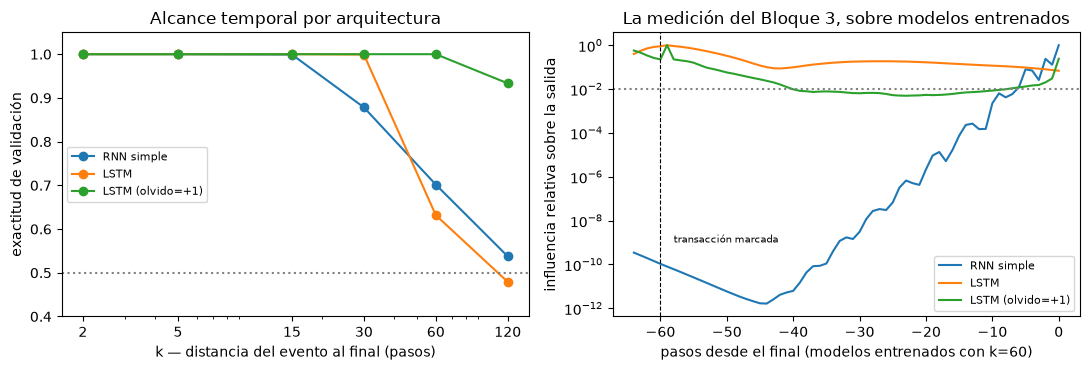

In [24]:
# Parte C: cerrar el círculo con el Bloque 3.
# Sobre los modelos YA ENTRENADOS mido lo mismo que medí a mano allá: cuánto
# influye cada paso de la entrada sobre la decisión final. Uso autograd en vez de
# diferencias finitas, que es la misma derivada pero sin el error de truncamiento
# que mete epsilon.
K_DIAG = 60


def influencia_entrada(modelo, X, n=256):
    """|d logit_final / d monto_t| promediado sobre un lote -> arreglo (T,)."""
    x = torch.tensor(X[:n]).clone().requires_grad_(True)
    g, = torch.autograd.grad(modelo(x).sum(), x)
    return g[:, :, 0].abs().mean(0).detach().numpy()      # canal del monto


print(f"Modelos entrenados con k={K_DIAG} (semilla 0). La transacción que decide la")
print(f"etiqueta está en el índice {PREAMBULO}, o sea {K_DIAG} pasos antes del final.\n")

curvas = {}
for nombre, _ in ARQUITECTURAS:
    m, Xk, _yk = modelos_guardados[(nombre, K_DIAG)]
    s = influencia_entrada(m, Xk)
    curvas[nombre] = s
    rel_marca = s[PREAMBULO] / s.max()                    # ¿la ve o no la ve?
    caida = s[PREAMBULO] / s[-1]                          # marca vs. último paso
    factor = caida ** (1.0 / K_DIAG)                      # retención por paso
    if factor < 1:
        alcance = np.log(0.01) / np.log(factor)           # dónde cruza el 1%
        txt = f"retención por paso {factor:.3f} -> alcance efectivo {alcance:4.1f} pasos"
    else:
        txt = "sin decaimiento: el paso marcado es el MÁS influyente de la secuencia"
    print(f"{nombre:<17} influencia de la marca / máximo = {rel_marca:.2e}   {txt}")

f_b3 = 0.3161
print(f"\nBloque 3 (celda NO entrenada, w_h=0.5): retención {f_b3:.3f} por paso"
      f" -> alcance efectivo {np.log(0.01)/np.log(f_b3):.1f} pasos")

import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for nombre, _ in ARQUITECTURAS:
    ax[0].plot(VALORES_K, [resultados[nombre][k][0] for k in VALORES_K], "o-", label=nombre)
ax[0].axhline(0.5, ls=":", c="gray")
ax[0].set_xscale("log"); ax[0].set_xticks(VALORES_K); ax[0].set_xticklabels(VALORES_K)
ax[0].set_xlabel("k — distancia del evento al final (pasos)")
ax[0].set_ylabel("exactitud de validación"); ax[0].set_ylim(0.4, 1.05)
ax[0].set_title("Alcance temporal por arquitectura"); ax[0].legend(fontsize=8)

for nombre, _ in ARQUITECTURAS:
    s = curvas[nombre]
    ax[1].semilogy(np.arange(len(s)) - (len(s) - 1), s / s.max(), label=nombre)
ax[1].axvline(-K_DIAG, ls="--", c="k", lw=0.8)
ax[1].text(-K_DIAG + 2, 1e-9, "transacción marcada", fontsize=7)
ax[1].axhline(0.01, ls=":", c="gray")
ax[1].set_xlabel(f"pasos desde el final (modelos entrenados con k={K_DIAG})")
ax[1].set_ylabel("influencia relativa sobre la salida")
ax[1].set_title("La medición del Bloque 3, sobre modelos entrenados"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

### Tabla de resultados y conclusión — Bloque 7

**La tarea.** La etiqueta la decide el monto de una sola transacción, la que viene marcada, y esa
transacción está a $k$ pasos del final. Todo lo demás es ruido con la misma distribución en las dos clases.
Además cada secuencia lleva siempre un monto alto y uno bajo: si el marcado es el alto, el bajo cae en otra
posición al azar, y al revés. Así el promedio, el máximo, el mínimo y la desviación quedan inservibles, y
el control con variables agregadas lo confirma: sale 0.47, azar. Exactitud de validación, promedio de 3
semillas, `hidden_size = 32` en las tres arquitecturas.

| k (distancia) | exactitud RNN | exactitud LSTM | LSTM (olvido inicial = +1) |
|--:|--:|--:|--:|
| 2 | 1.000 | 1.000 | 1.000 |
| 5 | 1.000 | 1.000 | 1.000 |
| 15 | 0.999 | 1.000 | 1.000 |
| 30 | 0.878 | 0.999 | 1.000 |
| 60 | 0.702 | 0.632 | 1.000 |
| 120 | 0.537 | 0.479 | 0.933 |

Agregué $k=60$ y $k=120$ a los cuatro valores pedidos porque con $T=30$ ninguna de las dos arquitecturas se
rompía y la tabla no iba a medir nada. La tercera columna es una ablación: el mismo `DetectorFraude`, pero
con el sesgo de la compuerta de olvido inicializado en $+1$ en lugar de casi cero.

#### ¿A partir de qué distancia deja de aprender la RNN simple?

Hasta $k=15$ va perfecta. En $k=30$ se cae a 0.878, y con una desviación de 0.089 entre semillas, o sea que
a veces aprende y a veces no. En $k=60$ queda en 0.702 y en $k=120$ en 0.537, que ya es azar. El quiebre
está entre 15 y 30 pasos.

#### ¿Coincide con lo que medí en el Bloque 3?

A medias, y ahí está lo interesante. En el Bloque 3, con los pesos fijos del enunciado y sin entrenar, la
retención me salió de 0.316 por paso, que da un alcance de 4.0 pasos al umbral del 1 %. Si eso valiera tal
cual, la RNN tendría que fallar desde $k=5$, y no falla: acierta 1.000 hasta $k=15$.

Repetí la misma medición sobre la RNN ya entrenada con $k=60$ (Parte C, con autograd en vez de diferencias
finitas) y la retención sube a 0.679 por paso, que son 11.9 pasos de alcance. Tiene sentido: entrenar
empuja $w_h(1-h^2)$ hacia arriba y acerca la celda a un pestillo saturado, así que el alcance se triplica.
Lo que no cambia es la forma de la curva. Sigue siendo un decaimiento geométrico, y un decaimiento
geométrico tiene techo: con 0.679 por paso, la influencia de la transacción marcada a 60 pasos de distancia
es de $8\times10^{-11}$ respecto del paso más reciente. Con esa señal no hay nada que aprender.

Entonces el número del Bloque 3 se quedó corto, porque venía de una celda sin entrenar. Pero el alcance
medido sobre el modelo entrenado, unos 12 pasos, sí predice bien dónde se cae la exactitud: entre 15 y 30,
y muerta en 60. La ley se cumple aunque la constante haya cambiado.

#### Lo que no esperaba

A $k=60$ la LSTM por omisión sale peor que la RNN, 0.632 contra 0.702. La que aguanta hasta 120 es la de la
ablación, que es el mismo modelo con otra inicialización. La explicación viene del Bloque 5: el eslabón de
la cadena en la LSTM es $f_t$, y con la inicialización por omisión de PyTorch los sesgos salen de
$\mathcal{U}(-1/\sqrt{32},\, 1/\sqrt{32})$, así que $f$ arranca en $\sigma(0)\approx 0.5$ y el expediente se
desvanece como $0.5^{60}\approx 10^{-18}$. Es el mismo problema de la RNN con otro nombre. La LSTM puede
aprender a subir $f_t$, pero para aprenderlo necesita un gradiente que ya se desvaneció. Arrancar en
$f\approx 0.73$ rompe ese círculo y la tarea se vuelve fácil.

La medición de la Parte C separa los dos fracasos, y no son el mismo. En la RNN entrenada la sensibilidad a
la transacción marcada es $8\times10^{-11}$ del máximo: la información nunca llega al final. En la LSTM por
omisión esa misma transacción es el paso más influyente de toda la secuencia ($1.0$ del máximo) y aun así
la exactitud se queda en 0.63: el camino existe, lo que faltó fue entrenamiento. En la tabla de exactitud
los dos casos se ven parecidos, pero uno se arregla entrenando más y el otro no se arregla nunca.

#### Lo que le diría al área de riesgos

Con `hidden_size=32` y este presupuesto de entrenamiento, una RNN simple lee con confianza las últimas 15
transacciones de la tarjeta, más o menos. Si el patrón que se quiere atrapar es una prueba pequeña y la
escalada mucho después, esa arquitectura no lo va a ver por más datos que se le den. La LSTM con la
compuerta de olvido bien inicializada llega a 120 pasos sin problema. De ahí para arriba yo no agrandaría
la LSTM, agregaría atención sobre el pasado.

---
## Bloque 8 — Análisis (8 puntos)

En sus propias palabras, 3 a 6 líneas cada una.

1. El área de riesgos quiere usar una LSTM **bidireccional** para bloquear transacciones en el momento de
   la autorización. Explique por qué eso es imposible, y qué le propondría en su lugar.
2. Un compañero normaliza los montos dividiendo entre el máximo **de todo el conjunto de datos**, incluidos
   los de validación. Explique qué tipo de error es ese y cómo afectaría los resultados que reportó hoy.
3. La LSTM de este laboratorio tiene una sola variable por paso (el monto). En producción cada transacción
   trae monto, hora, canal, país y comercio. ¿Qué cambia exactamente en el código, y qué **no** cambia?

### Sus respuestas — Bloque 8

**1. LSTM bidireccional para bloquear en el momento de la autorización.**
No se puede por causalidad, no por implementación. La bidireccional corre la secuencia también de derecha a
izquierda, así que para decidir sobre la transacción actual necesita las que vienen después, y en el momento
de autorizar esas todavía no existen. Si alguien la entrena con historiales completos va a ver métricas
buenísimas en el laboratorio que se le caen en producción, porque en la evaluación estaba usando el futuro.
Yo propondría una LSTM normal corriendo en línea, guardando `(h, c)` por tarjeta y actualizándolo con cada
transacción nueva: cuesta un paso por autorización en vez de reprocesar toda la historia. La bidireccional
sí sirve, pero para el análisis forense al cierre del día, cuando la secuencia ya está cerrada.

**2. Normalizar dividiendo entre el máximo de todo el conjunto.**
Eso es fuga de datos en el preprocesamiento: el máximo se calculó con información de validación, que el
modelo no debería haber visto. Por un lado la exactitud de validación queda optimista y deja de servir como
estimado de lo que va a pasar con datos nuevos, así que los números del Bloque 6 y del Bloque 7 dejarían de
ser comparables. Por otro lado, en producción no existe "el máximo del conjunto", porque las transacciones
llegan una por una; habría que congelar el escalador del entrenamiento, y si llega un monto mayor al máximo
histórico el sistema se comporta distinto de como fue validado. Lo correcto es ajustar el escalador solo
con entrenamiento y aplicarlo tal cual al resto. Con datos de fechas, además, conviene partir por tiempo.

**3. De una variable por paso a monto, hora, canal, país y comercio.**
Cambia la entrada y poco más. El tensor pasa de `(batch, 30, 1)` a `(batch, 30, F)` y el modelo a
`nn.LSTM(input_size=F, ...)`. Monto y hora se escalan con estadísticos de entrenamiento, y a la hora
conviene meterla como seno y coseno para que las 23:00 y las 00:00 queden cerca. Canal, país y comercio no
pueden entrar como enteros crudos: cada uno va por una `nn.Embedding` y los vectores se concatenan con las
numéricas. Eso agrega parámetros y obliga a manejar categorías raras o no vistas con un token `<UNK>`. No
cambia nada de la estructura: la recurrencia es la misma ecuación, se sigue clasificando con `h_n[-1]`, la
capa de salida sigue siendo un `Linear(oculto, 1)` y el bucle de entrenamiento queda igual.

---
## Bloque 9 — Conclusión (5 puntos)

Dos preguntas. Ninguna tiene respuesta correcta; sí tienen respuesta **honesta**.

1. ¿En qué punto exacto de este laboratorio algo dejó de tener sentido para usted, y qué hizo para salir de
   ahí? Si nada se le atoró, diga qué parte le resultó más fácil de lo que esperaba y por qué.
2. Usted midió el desvanecimiento del gradiente en el Bloque 3 antes de que la clase se lo explicara del
   todo. ¿Qué le dio medirlo que no le habría dado leerlo?

### Sus respuestas — Bloque 9

**1.** Donde me atoré fue en el Bloque 7, y no por el código. Mi primer diseño de la tarea ponía un monto
atípico (0.95) solo en la clase de fraude y dejaba el resto como ruido. Entrené y me salió que la RNN
simple acertaba 1.000 a 30 pasos de distancia, que es lo contrario de todo lo que el laboratorio venía
armando desde el Bloque 3, donde yo mismo había medido que la memoria se apagaba en 4 pasos. Estuve un
rato tratando de acomodar el resultado, pensando en escribir algo como "en la práctica la RNN aguanta más
de lo que dice la teoría". Lo que me sacó de ahí fue preguntarme qué estaba midiendo de verdad. Si el valor
raro aparece solo en una clase, la pregunta que el modelo resuelve no es "¿qué pasó en el paso $T-k$?" sino
"¿apareció algo raro en algún momento?", y esa segunda pregunta no depende del orden: una celda saturada la
contesta con un pestillo y le da igual la distancia. Volví a armar los datos con un distractor compensado,
donde las dos clases llevan un monto alto y uno bajo y lo único que cambia es cuál está marcado, y ahí sí
apareció la curva. Me quedó claro que cuando un resultado contradice una medición mía anterior, lo más
probable es que el experimento esté mal diseñado y no que haya descubierto algo.

**2.** Me dio la escala. "El gradiente se desvanece" lo había leído varias veces y lo tenía guardado como
una advertencia vaga, tipo "las RNN tienen mala memoria". Ver el número es distinto: en una secuencia de
apenas 20 pasos, el último influye 1,930,463,265 veces más que el primero. Nueve órdenes de magnitud no son
poca memoria, son que esa información no está.

También hubo dos cosas que no esperaba. Una es que medirlo me dejó una predicción concreta, 4 pasos con
esos pesos y 12 en el modelo entrenado, que después pude contrastar contra la tabla del Bloque 7 y ver
dónde le atinaba y dónde no; leyéndolo no habría tenido nada que contrastar. La otra es que la misma
medición me terminó sirviendo de herramienta: aplicada a los modelos ya entrenados fue lo que me dejó
distinguir el fracaso de la RNN, donde la señal no llega, del de la LSTM por omisión, donde la señal llega
pero le faltó entrenamiento. En la tabla de exactitud esos dos casos se veían casi iguales. Una fórmula que
uno se memoriza no se puede correr sobre un modelo para ver qué le pasa; una medición sí.